# 13 · H1-vs-H2 query-mask analysis

Which heads (before the goal-head layers) carry "what task comes next", and *how*?
- **H1 — induction ordering**: the next task = the one *after* the last-done task in the listing.
- **H2 — set-difference**: the next task = the task-set minus what's already done.

Contrastive **SRC/DST** setup (`src.diff.h1h2`): 5 predicate roles **A**=anchor, **C**=frontier,
**D**=src_targ, **B**=dst_h1, **E**=dst_targ.
- **SRC** tasks `[A,C,D,B]`, prefill `{A,C,B}` (C written last), target **D**.
- **DST** tasks `[A,C,B,E(,D)]`, prefill `{A}`, native next = **C**.
- Patch SRC's pivot query into DST → the outcome dissociates the mechanism: **H1→B**, **H2→E**,
  **COPY→D**, **NO-OP→C**.

A trained **query mask** (`train_query_mask`) selects heads at layers `< L_READ` whose query, blended
`q = m·q_src + (1−m)·q_dst` at the pivot, flips the collapsed goal-head **gaze** onto one hypothesis's
target span. This notebook, for a config `(λ, k, L_READ, intervention, hypothesis)`:
1. loads that trained mask + the goal heads (the gaze/readout **judge**),
2. rebuilds the same SRC/DST pair and the clean(SRC)→DST query patch,
3. tracks **(i)** the gaze-shift onto the target span (the training objective) and **(ii)** a short
   generation with the pivot query kept patched from clean(SRC), judged for the implemented task,
4. GoalScope + OVReader debugging (OVReader **off** by default).

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os, sys, glob, json
os.environ["CUDA_VISIBLE_DEVICES"] = "7"          # single free GPU (inference only)
os.environ["TOKENIZERS_PARALLELISM"] = "false"
sys.path.append(".."); sys.path.append("../..")

import torch, baukit
from contextlib import nullcontext
from rich import print as rich_print
from rich.markup import escape
from rich.panel import Panel
from rich.text import Text
from rich.table import Table

import src.diff.functional as FUNC
import src.diff.h1h2 as H
import src.diff.h1h2_mask as M
from src.goals.head_loc_attn import HeadMask
from src.goals.goalscope import OVReader, head_additive_generate, _build_goalscope_prompt, _build_causality_prompt
from src.tokens import prepare_input, find_token_range
from scripts.evaluation.ablation_common import judge_implements   # oracle: does gen implement a desc?
from src.utils import env_utils

torch.set_grad_enabled(False)
MODEL = "Qwen/Qwen2.5-Coder-32B-Instruct"
FUNC.setup(MODEL)          # loads model (eager) + goal-head mask; binds FUNC globals
mt = FUNC.mt
SLUG = mt.name.split("/")[-1]

2026-09-14 21:28:46 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models


Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

Qwen/Qwen2.5-Coder-32B-Instruct
n_heads=40  n_kv_heads=8  group=5  head_dim=128  n_layer=64
GOAL_HEADS     : 122  (layers 28–55)
BOUNDARY_HEADS : 140  (layers 11–62)
UNION_HEADS    : 228


In [27]:
# ── config ───────────────────────────────────────────────────────────────────────────────────
DATATYPE     = "list[str]"                    # int | str | list[int] | list[str]
LANG         = "python"
L_READ       = 40                             # collapse-read layer (maskable heads at layers < L_READ)
INTERVENTION = "free_form"     # block_head_communication | free_form | mlps_frozen
HYPOTHESIS   = "h1"                           # h1 (->B) | h2 (->E) | copy (->D) | noop (->C)
PATCH_LAST_K = 3                              # trailing query positions patched (1 = pivot only)
LAM_DIR      = None                           # None for standard runs; e.g. "lam1.0" if from --lambda_sweep

# pair selection — MUST match the training run so the cache/spec line up
N_PAIRS      = 512
SEED         = 123
PAIR_IDX     = 0                              # which spec from sample_pairs to analyse
STUB         = "var_eq"
SRC_TARG_IN_DST = False

# debugging / generation
SHOW_GOALSCOPE = True
SHOW_OVREADER  = True                        # OFF by default (global knob)
GEN_NEW        = 24
OV_LAYERS      = list(range(38, 48, 2)); STEER_BAND = (35, 46); ALPHA_OV = 0.15; MAXNEW_OV = 64
MODE           = "faithfulness"

# ── locate the trained mask ──
_dt = DATATYPE.replace("[", "").replace("]", "")
_root = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "evaluation", "h1h2_mask", SLUG, f"L{L_READ}", _dt)
_lam = f"{LAM_DIR}/" if LAM_DIR else ""
MASK_PATH = os.path.join(_root, INTERVENTION, f"k{PATCH_LAST_K}", _lam.rstrip("/") if _lam else "", HYPOTHESIS, "mask.pt")
MASK_PATH = os.path.normpath(MASK_PATH)
if not os.path.exists(MASK_PATH):
    print("MASK NOT FOUND:", MASK_PATH, "\navailable masks under this L/datatype:")
    for p in sorted(glob.glob(os.path.join(_root, "**", "mask.pt"), recursive=True)):
        print("  ", os.path.relpath(p, _root))
else:
    print("mask:", os.path.relpath(MASK_PATH, env_utils.DEFAULT_RESULTS_DIR))

mask: evaluation/h1h2_mask/Qwen2.5-Coder-32B-Instruct/L40/liststr/free_form/k3/h1/mask.pt


In [35]:
# OPTIONAL — use the top-250 goal-head set (patch + readout), which gave near-perfect kv transfer.
import json
_p = "../../head_sets/Qwen2.5-Coder-32B-Instruct/goal_topk/goal__lam20_top250.json"
GOAL_HEADS_250 = [tuple(h) for h in json.load(open(_p))]

In [36]:
# ── load the trained query mask + the goal heads (the judge) ──
blob = torch.load(MASK_PATH, map_location=mt.device, weights_only=False)
mask = HeadMask(len(blob["layers"]), blob["mask_values"].shape[1], mask_layers=blob["layers"])
mask.values.data.copy_(blob["mask_values"]); mask = mask.to(mt.device)
zero_mask = HeadMask(len(blob["layers"]), blob["mask_values"].shape[1], mask_layers=blob["layers"])
zero_mask.values.data.zero_(); zero_mask = zero_mask.to(mt.device)   # clean baseline (no q-patch)

# goal_heads = M.mt_goal_heads(mt)              # == FUNC.GOAL_HEADS — the gaze/readout judge
goal_heads = GOAL_HEADS_250
cfg = blob.get("config", {})
sel = blob.get("selected_heads", [])
rich_print(f"[bold]mask[/] hyp={blob['hypothesis']} interv={blob['intervention']} "
           f"L_READ={blob['l_read']} k={cfg.get('patch_last_k','?')} λ={cfg.get('lambda_sparse','?')} "
           f"epoch={blob.get('epoch','?')}")
hist = blob.get("history", {})
if hist:
    rich_print(f"      final: mass={hist['mass'][-1]:.3f}  task={hist['task'][-1]:.3f}  "
               f"sparse={hist['sparse'][-1]:.3f}  n_selected={blob.get('n_selected', len(sel))}")
rich_print(f"      judge = {len(goal_heads)} goal heads")
sel_layers = sorted({l for l, _ in sel})
rich_print(f"      mask selects {len(sel)} heads across layers {sel_layers[:8]}{'…' if len(sel_layers)>8 else ''}")

mask hyp=h1 interv=free_form L_READ=40 k=3 λ=1.0 epoch=31

final: mass=0.313  task=1.911  sparse=0.075  n_selected=123

judge = 250 goal heads

mask selects 123 heads across layers [4, 9, 13, 14, 16, 20, 21, 22]…

mask-selected = 123 heads (layers < L_READ=40)   goal/judge = 250 heads (layers 0–63)

overlap (selected AND goal) : 12  = 10% of selected / 5% of goal heads

selected, strictly upstream of goal band (<L0) : 0

selected, inside goal band but NOT a goal head       : 111

shared heads: L29.h18, L30.h8, L30.h25, L31.h32, L34.h25, L38.h2, L39.h8, L39.h14, L39.h31, L39.h32, L39.h33, 
L39.h34

    per-layer: selected vs goal    
 layer ┃ #selected ┃ #goal ┃ #both 
━━━━━━━╇━━━━━━━━━━━╇━━━━━━━╇━━━━━━━
     0 │         · │    12 │     · 
     1 │         · │     1 │     · 
     4 │         1 │     · │     · 
     9 │         1 │     · │     · 
    11 │         · │     1 │     · 
    13 │         1 │     · │     · 
    14 │         1 │     · │     · 
    16 │         1 │     · │     · 
    20 │         2 │     · │     · 
    21 │         2 │     · │     · 
    22 │         1 │     · │     · 
    23 │         1 │     2 │     · 
    24 │         2 │     · │     · 
    25 │         2 │     · │     · 
    27 │         1 │     · │     · 
    28 │         · │     1 │     · 
    29 │         3 │     3 │     1 
    30 │         7 │     3 │     2 
    31 │         5 │     4 │     1 
    32 │         7 │     2 │     · 
    33 │         9 │     1 │     · 
    34 │        10 │     4 │     1 
    35 │         5 │     3 │     · 
    36 │        10 │     · │     · 
    37 │        13 │     3 │     · 
    38 │        23 │     2 │     1 
    39 │        15 │    10 │     6 
    40 │         · │    10 │     · 
    41 │         · │     7 │     · 
    42 │         · │     6 │     · 
    43 │         · │    15 │     · 
    44 │         · │     8 │     · 
    45 │         · │    14 │     · 
    46 │         · │    17 │     · 
    47 │         · │    20 │     · 
    48 │         · │     8 │     · 
    49 │         · │    16 │     · 
    50 │         · │     7 │     · 
    51 │         · │    11 │     · 
    52 │         · │    10 │     · 
    53 │         · │     7 │     · 
    54 │         · │     4 │     · 
    55 │         · │     6 │     · 
    56 │         · │     4 │     · 
    59 │         · │     5 │     · 
    60 │         · │    11 │     · 
    61 │         · │     6 │     · 
    62 │         · │     2 │     · 
    63 │         · │     4 │     ·

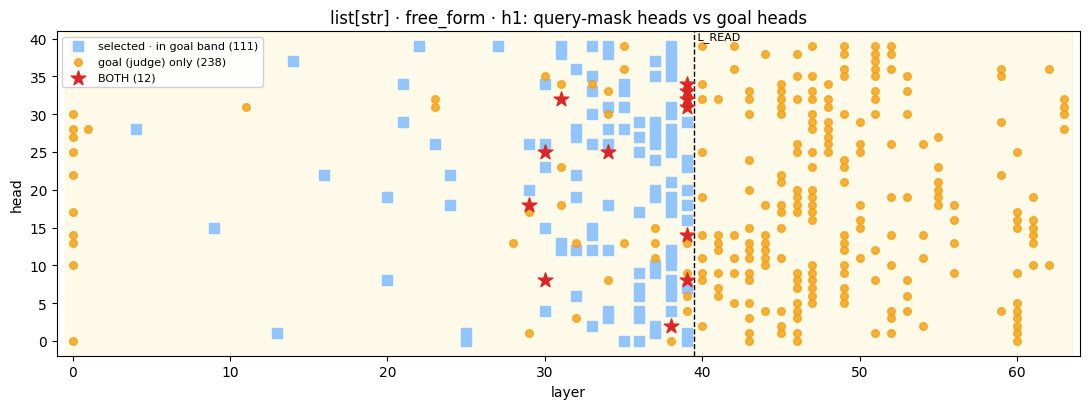

In [37]:
# ── selected (query-mask) heads vs goal heads (the judge): where do they sit? ──
import matplotlib.pyplot as plt

sel_set  = {tuple(x) for x in (sel or [])}          # mask query-side heads (layers < L_READ)
goal_set = {tuple(x) for x in goal_heads}           # readout/judge heads
both     = sel_set & goal_set
sel_only = sel_set - goal_set
goal_only = goal_set - sel_set

g_lo, g_hi = min(l for l,_ in goal_set), max(l for l,_ in goal_set)
sel_up   = {(l,h) for (l,h) in sel_only if l < g_lo}     # strictly upstream of the goal band
sel_band = {(l,h) for (l,h) in sel_only if g_lo <= l}    # in/above goal band but not a goal head

rich_print(f"[bold]mask-selected[/] = {len(sel_set)} heads (layers < L_READ={L_READ})   "
           f"[bold]goal/judge[/] = {len(goal_set)} heads (layers {g_lo}–{g_hi})")
rich_print(f"  overlap (selected AND goal) : [bold]{len(both)}[/]  "
           f"= {100*len(both)/max(len(sel_set),1):.0f}% of selected / {100*len(both)/len(goal_set):.0f}% of goal heads")
rich_print(f"  selected, strictly upstream of goal band (<L{g_lo}) : {len(sel_up)}")
rich_print(f"  selected, inside goal band but NOT a goal head       : {len(sel_band)}")
if both:
    rich_print("  shared heads: " + ", ".join(f"L{l}.h{h}" for l,h in sorted(both)))

# per-layer counts
tbl = Table(title="per-layer: selected vs goal", show_edge=False)
for c in ("layer","#selected","#goal","#both"): tbl.add_column(c, justify="right")
for L in range(mt.n_layer):
    ns = sum(1 for l,_ in sel_set if l==L); ng = sum(1 for l,_ in goal_set if l==L)
    nb_ = sum(1 for l,_ in both if l==L)
    if ns or ng:
        tbl.add_row(str(L), str(ns) if ns else "·", str(ng) if ng else "·", f"[bold red]{nb_}[/]" if nb_ else "·")
rich_print(tbl)

# scatter: layer (x) vs head (y)
fig, ax = plt.subplots(figsize=(11, 4.2))
if sel_up:   ax.scatter([l for l,_ in sel_up],   [h for _,h in sel_up],   s=42, marker="s", c="#3b82f6", label=f"selected · upstream ({len(sel_up)})")
if sel_band: ax.scatter([l for l,_ in sel_band], [h for _,h in sel_band], s=42, marker="s", c="#93c5fd", label=f"selected · in goal band ({len(sel_band)})")
if goal_only:ax.scatter([l for l,_ in goal_only],[h for _,h in goal_only],s=30, marker="o", c="#f59e0b", label=f"goal (judge) only ({len(goal_only)})", alpha=.8)
if both:     ax.scatter([l for l,_ in both],     [h for _,h in both],     s=120, marker="*", c="#dc2626", label=f"BOTH ({len(both)})", zorder=5)
ax.axvline(L_READ-0.5, ls="--", c="k", lw=1); ax.text(L_READ-0.5, ax.get_ylim()[1], " L_READ", va="top", fontsize=8)
ax.axvspan(g_lo-0.5, g_hi+0.5, color="#fde68a", alpha=.18, zorder=0)
ax.set_xlabel("layer"); ax.set_ylabel("head"); ax.set_title(f"{DATATYPE} · {INTERVENTION} · {HYPOTHESIS}: query-mask heads vs goal heads")
ax.legend(loc="upper left", fontsize=8, framealpha=.9); ax.set_xlim(-1, mt.n_layer); plt.tight_layout(); plt.show()


In [38]:
# ── rebuild the SAME spec + SRC/DST prompts; inspect the contrastive form ──
specs = H.sample_pairs(DATATYPE, N_PAIRS, lang=LANG, seed=SEED)
spec = specs[PAIR_IDX]
P = H.build_prompts(mt, spec, stub=STUB, src_targ_in_dst=SRC_TARG_IN_DST)

def _desc(pid): return {p.id: p.description for p in P["dst_inst"].task.predicates}.get(pid, pid)
rich_print(f"[bold]roles[/]  A(anchor)={spec.anchor}  C(frontier)={spec.frontier}  "
           f"D(src_targ)={spec.src_targ}  B(dst_h1)={spec.dst_h1}  E(dst_targ)={spec.dst_targ}")
rich_print("[bold]outcomes if SRC pivot-q patched into DST:[/]")
for label, (role, pid, desc) in P["outcomes"].items():
    tag = "  <-- TARGET" if M.HYPOTHESIS_ROLE[HYPOTHESIS] == role else ""
    rich_print(f"   {escape(label)} : {pid} = [italic]{escape(desc)}[/]{tag}")

rich_print(Panel(escape(P["src_prompt"]), title="[bold]SRC prompt (tasks A,C,D,B · prefill A,C,B · target D)[/]",
                 title_align="left", border_style="green", padding=(1, 1)))
rich_print(Panel(escape(P["dst_prompt"]), title="[bold]DST prompt (tasks A,C,B,E[,D] · prefill A · native C)[/]",
                 title_align="left", border_style="magenta", padding=(1, 1)))

roles  A(anchor)=count_short  C(frontier)=distinct_count  D(src_targ)=total_uppercase_letters  
B(dst_h1)=total_length  E(dst_targ)=any_empty

outcomes if SRC pivot-q patched into DST:

H1 (induction)  -> B : total_length = the total number of characters across all words  <-- TARGET

H2 (set-diff)   -> E : any_empty = whether any word is empty

COPY            -> D : total_uppercase_letters = the total number of uppercase letters across all words

NO-OP (native)  -> C : distinct_count = the number of distinct words

╭─ SRC prompt (tasks A,C,D,B · prefill A,C,B · target D) ─────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ <|im_start|>system                                                                                              │
│ You are a helpful assistant proficient in programming. Always wrap your code inside <code></code> blocks. Just  │
│ the code, no need to comment or explain.<|im_end|>                                                              │
│ <|im_start|>user                                                                                                │
│ Write a Python program that implements a function `func` which, given a list of strings `words`, computes:      │
│ (1) the number of words shorter than three characters                                                           │
│ (2) the number of distinct words                                                                                │
│ (3) the total number of uppercase letters across all words                                                      │
│ (4) the total number of characters across all words                                                             │
│ <|im_end|>                                                                                                      │
│ <|im_start|>assistant                                                                                           │
│ <code>                                                                                                          │
│ def func(words: list[str]):                                                                                     │
│     a = sum(1 for w in words if len(w) < 3)                                                                     │
│     b = sum(len(w) for w in words)                                                                              │
│     c = len(set(words))                                                                                         │
│     d =                                                                                                         │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─ DST prompt (tasks A,C,B,E[,D] · prefill A · native C) ─────────────────────────────────────────────────────────╮
│                                                                                                                 │
│ <|im_start|>system                                                                                              │
│ You are a helpful assistant proficient in programming. Always wrap your code inside <code></code> blocks. Just  │
│ the code, no need to comment or explain.<|im_end|>                                                              │
│ <|im_start|>user                                                                                                │
│ Write a Python program that implements a function `func` which, given a list of strings `words`, computes:      │
│ (1) the number of words shorter than three characters                                                           │
│ (2) the number of distinct words                                                                                │
│ (3) the total number of characters across all words                                                             │
│ (4) whether any word is empty                                                                                   │
│ <|im_end|>                                                                                                      │
│ <|im_start|>assistant                                                                                           │
│ <code>                                                                                                          │
│ def func(words: list[str]):                                                                                     │
│     a = sum(1 for w in words if len(w) < 3)                                                                     │
│     b =                                                                                                         │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [39]:
# ── build the pair cache: caches clean(SRC) pivot query, sets the DST patch positions + spans ──
cache = M.build_pair_cache(mt, spec, L_READ, INTERVENTION, H.build_prompts,
                           stub=STUB, src_targ_in_dst=SRC_TARG_IN_DST, patch_last_k=PATCH_LAST_K)
cache = cache.to(mt.device)
tgt_idx = M.target_span_idx(cache, HYPOTHESIS)             # DST predicate-span index of the hypothesis target
preds = [p.id for p in P["dst_inst"].task.predicates]
rich_print(f"pivot @ {cache.dst_pivot}  ·  patch positions {list(cache.patch_positions)}  "
           f"(clean-SRC query blended here)")
rich_print(f"DST predicate spans (task order {preds}): "
           + "  ".join(f"{pid}={tuple(s)}" for pid, s in zip(preds, cache.spans)))
rich_print(f"target span idx for {HYPOTHESIS} = {tgt_idx} ({preds[tgt_idx]} = [italic]{escape(_desc(preds[tgt_idx]))}[/])")

pivot @ 140  ·  patch positions [138, 139, 140]  (clean-SRC query blended here)

DST predicate spans (task order ['count_short', 'distinct_count', 'total_length', 'any_empty']): count_short=(66, 
74)  distinct_count=(78, 83)  total_length=(87, 95)  any_empty=(99, 104)

target span idx for h1 = 2 (total_length = the total number of characters across all words)

## (i) Gaze-shift onto the target task — the training objective

`collapse_gaze_per_pos` computes the goal heads' value-weighted pivot→span attention when they read the
collapsed residual `h_read`. Compare **clean** (mask=0, no q-patch → gaze on native **C**) vs **patched**
(the trained mask blends clean(SRC) query in → gaze should move to the hypothesis target).

In [40]:
readers = M._GoalReaders.build(mt, goal_heads)

def gaze_masses(m):
    h = M.h_read(mt, m, cache, INTERVENTION)                # collapsed residual under this mask
    per = M.collapse_gaze_per_pos(readers, h, cache.dst_pivot)
    _, p_t, masses = M.gaze_objective(per, cache.spans, tgt_idx)
    total = float(sum(masses)) or 1.0
    return [float(x) / total for x in masses], float(p_t)

frac_clean, _   = gaze_masses(zero_mask)
frac_patched, p = gaze_masses(mask)

t = Table(title=f"goal-head gaze mass by DST task span  ·  target = {HYPOTHESIS} ({preds[tgt_idx]})")
t.add_column("span (pred)", justify="left"); t.add_column("clean", justify="right")
t.add_column("patched", justify="right"); t.add_column("Δ", justify="right")
for i, pid in enumerate(preds):
    star = " ★" if i == tgt_idx else ""
    t.add_row(f"{pid}{star}", f"{frac_clean[i]:.3f}", f"{frac_patched[i]:.3f}",
              f"{frac_patched[i]-frac_clean[i]:+.3f}", style=("bold" if i == tgt_idx else None))
rich_print(t)
rich_print(f"[bold]p(target span) — clean {frac_clean[tgt_idx]:.3f} → patched {frac_patched[tgt_idx]:.3f}[/]  "
           f"(gaze_objective p_target={p:.3f})")

# ── per-token gaze distribution over the DST task span (clean / patched / Δ) ──
#    EXACTLY the training objective's value-weighted gaze (collapse_gaze_per_pos = softmax(q·k/√d)·‖v‖,
#    closed-form on the collapsed h_read @ L_READ, mean over goal heads) — the same per-pos object the
#    mass table above sums.  cf. the value-weighted ATTN_VIS in notebooks/diff/04.
import numpy as np

TASK_POS  = list(range(min(s[0] for s in cache.spans), max(s[1] for s in cache.spans)))
task_toks = [mt.tokenizer.decode([int(cache.dst_ids[0][j])]) for j in TASK_POS]

per_clean   = M.collapse_gaze_per_pos(readers, M.h_read(mt, zero_mask, cache, INTERVENTION), cache.dst_pivot)
per_patched = M.collapse_gaze_per_pos(readers, M.h_read(mt, mask,      cache, INTERVENTION), cache.dst_pivot)
a_clean   = per_clean[TASK_POS].float().cpu().numpy()      # raw (un-normalized) value-weighted gaze
a_patched = per_patched[TASK_POS].float().cpu().numpy()

rich_print(f"\n[bold]goal-head pivot→TASK gaze[/]  (value-weighted, mean over {len(goal_heads)} judge heads; "
           f"green=+ / red=−)")
FUNC.show_delta_tokens(task_toks, a_clean,             "clean(DST)")
FUNC.show_delta_tokens(task_toks, a_patched,           "patched(DST)")
FUNC.show_delta_tokens(task_toks, a_patched - a_clean, "GAZE_DELTA · patched − clean")

# per-span mass (raw sum) — matches the numerator of the normalized mass table above
_off = TASK_POS[0]; _tset = set(TASK_POS)
def _span_mass(a, span):
    idx = [j - _off for j in range(span[0], span[1]) if j in _tset]
    return float(np.asarray(a)[idx].sum()) if idx else 0.0
rich_print(f"[dim]target span {preds[tgt_idx]} raw gaze mass:  clean {_span_mass(a_clean, cache.spans[tgt_idx]):.3f}"
           f" → patched {_span_mass(a_patched, cache.spans[tgt_idx]):.3f}"
           f"  (Δ {_span_mass(a_patched, cache.spans[tgt_idx]) - _span_mass(a_clean, cache.spans[tgt_idx]):+.3f})[/]")


   goal-head gaze mass by DST task span  ·   
         target = h1 (total_length)          
┏━━━━━━━━━━━━━━━━┳━━━━━━━┳━━━━━━━━━┳━━━━━━━━┓
┃ span (pred)    ┃ clean ┃ patched ┃      Δ ┃
┡━━━━━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━╇━━━━━━━━┩
│ count_short    │ 0.254 │   0.225 │ -0.030 │
│ distinct_count │ 0.396 │   0.168 │ -0.227 │
│ total_length ★ │ 0.226 │   0.519 │ +0.292 │
│ any_empty      │ 0.124 │   0.088 │ -0.036 │
└────────────────┴───────┴─────────┴────────┘

p(target span) — clean 0.226 → patched 0.519  (gaze_objective p_target=0.519)

goal-head pivot→TASK gaze  (value-weighted, mean over 250 judge heads; green=+ / red=−)

clean(DST)   (green +Δ / red −Δ, |Δ|max=0.713)

patched(DST)   (green +Δ / red −Δ, |Δ|max=0.646)

GAZE_DELTA · patched − clean   (green +Δ / red −Δ, |Δ|max=0.502)

target span total_length raw gaze mass:  clean 0.851 → patched 2.378  (Δ +1.527)

## (ii) Generation under the sustained query patch

Greedy-decode a few tokens while **continuously** blending the clean(SRC) pivot query into DST (the mask
applied at layers `< L_READ`, patch positions only). Cache-free (full re-forward each step) so the pivot
query stays clamped every step. Then the oracle judges which of the four outcome tasks the completion
implements.

In [41]:
def greedy_qpatch(mt, cache, m, max_new=24, use_patch=True):
    ids = cache.dst_ids.clone(); attn = cache.dst_attn.clone()
    eos = mt.tokenizer.eos_token_id; gen = []
    for _ in range(max_new):
        handles = M._q_blend_hooks(mt, m, cache) if use_patch else []
        try:
            logits = mt._model(input_ids=ids, attention_mask=attn).logits
        finally:
            for h in handles: h.remove()
        nxt = int(logits[0, -1].argmax())
        if nxt == eos: break
        s = mt.tokenizer.decode([nxt])
        gen.append(nxt)
        if "\n" in s: break                                 # one predicate line
        ids = torch.cat([ids, torch.tensor([[nxt]], device=ids.device)], dim=1)
        attn = torch.ones_like(ids)
    return mt.tokenizer.decode(gen, skip_special_tokens=True).strip()

clean_gen   = greedy_qpatch(mt, cache, zero_mask, GEN_NEW, use_patch=False)
patched_gen = greedy_qpatch(mt, cache, mask,      GEN_NEW, use_patch=True)
tail = P["dst_prompt"].rsplit("\n", 1)[-1]                  # the "    x =" pivot line
rich_print(f"[dim]pivot line:[/] {escape(tail)}")
rich_print(f"[magenta]clean DST gen   (expect NO-OP C):[/] {escape(clean_gen)}")
rich_print(f"[salmon1]patched gen     (expect {HYPOTHESIS} target):[/] {escape(patched_gen)}")

# judge the patched completion against each outcome task
rich_print("\n[bold]oracle: which task does the patched completion implement?[/]")
for label, (role, pid, desc) in P["outcomes"].items():
    v = judge_implements(patched_gen, desc)["verdict"]
    tag = " ★TARGET" if M.HYPOTHESIS_ROLE[HYPOTHESIS] == role else ""
    color = "green" if v == "YES" else "grey58"
    rich_print(f"   [{color}]{v:>3}[/] {escape(label)} ({pid}){tag}")

pivot line:     b =

clean DST gen   (expect NO-OP C): len(set(words))

patched gen     (expect h1 target): len(set(words))

oracle: which task does the patched completion implement?

 NO H1 (induction)  -> B (total_length) ★TARGET

 NO H2 (set-diff)   -> E (any_empty)

 NO COPY            -> D (total_uppercase_letters)

YES NO-OP (native)  -> C (distinct_count)

## GoalScope + OVReader debugging

GoalScope verbalizes the goal heads' aggregated OV write at the pivot (clean vs patched). OVReader reads
the layerwise residual → OV write (off by default; flip `SHOW_OVREADER`).

In [42]:
def qpatch_iface(m):
    def _if(mt, inputs, patches=None, model_kwargs=None):
        handles = M._q_blend_hooks(mt, m, cache)
        try:
            return mt._model(**dict(inputs), **dict(model_kwargs or {}))
        finally:
            for h in handles: h.remove()
    return _if

if SHOW_GOALSCOPE:
    FUNC.gsp = _build_causality_prompt(mt) if MODE == "causality" else None
    FUNC.goalscope_readout("  goalscope · clean DST @ pivot", P["dst_prompt"], cache.dst_pivot,
                           heads=goal_heads)
    FUNC.goalscope_readout("  goalscope · patched DST @ pivot", P["dst_prompt"], cache.dst_pivot,
                           heads=goal_heads, iface=qpatch_iface(mask))

if SHOW_OVREADER:
    ov = OVReader(mt, goal_heads)
    ln = lambda l: mt.layer_name_format.format(l); unt = lambda x: x[0] if isinstance(x, tuple) else x
    def ov_layerwise(iface=None):
        ctx = nullcontext()
        if iface is None:
            with torch.no_grad(), baukit.TraceDict(mt._model, [ln(l) for l in OV_LAYERS], retain_output=True) as tr:
                mt._model(input_ids=cache.dst_ids, attention_mask=cache.dst_attn)
        else:
            handles = M._q_blend_hooks(mt, mask, cache)
            try:
                with torch.no_grad(), baukit.TraceDict(mt._model, [ln(l) for l in OV_LAYERS], retain_output=True) as tr:
                    mt._model(input_ids=cache.dst_ids, attention_mask=cache.dst_attn)
            finally:
                for h in handles: h.remove()
        resid = {l: unt(tr[ln(l)].output)[0, cache.dst_pivot].detach().float().cpu() for l in OV_LAYERS}
        outs = ov.apply_probe(resid, mode=MODE, steer_layers=list(range(*STEER_BAND)),
                              max_new_tokens=MAXNEW_OV, alpha=ALPHA_OV)
        for l in OV_LAYERS: print(f"    OVReader L={l:2d}: {escape(outs[l])}")
    rich_print("[bold]OVReader · clean DST[/]");   ov_layerwise(iface=None)
    rich_print("[bold]OVReader · patched DST[/]"); ov_layerwise(iface=qpatch_iface(mask))

GoalScope[additive_norm]:   0%|          | 0/1 [00:00<?, ?it/s]

  goalscope · clean DST @ pivot  pos=140 ' =' => I'm counting unique elements using a set.

GoalScope[additive_norm]:   0%|          | 0/1 [00:00<?, ?it/s]

  goalscope · patched DST @ pivot  pos=140 ' =' => I'm counting unique elements using a set.

Building OV readers:   0%|          | 0/250 [00:00<?, ?it/s]

OVReader · clean DST

    OVReader L=38: I'm counting unique elements by using a set to store them.
    OVReader L=40: I'm counting unique elements by using a set to filter out duplicates.
    OVReader L=42: I'm tracking unique elements using a set to count distinct items.
    OVReader L=44: I'm identifying unique elements using a set to count distinct items.
    OVReader L=46: I'm identifying unique elements by using a set to count distinct items.


OVReader · patched DST

    OVReader L=38: To find the total number of unique elements in a list, you can use Python's `set` data structure to count unique elements. Use the `len()` function with `set` to count unique elements.
```python
total_unique_elements = len(set(data))
```
Here, `data` is a list where
    OVReader L=40: To find the total number of characters in a string, you can use the `sum` function with a generator expression to count the number of characters in a string by summing up the lengths of each character in the string. Here's how you can do it using Python:

```python
total_characters = sum(len(s
    OVReader L=42: I'm calculating the total number of unique elements in a list, considering only the unique items in a collection of lists or strings, where each item is treated as a set of unique elements. This accounts for duplicates, meaning if you have a list of lists, it counts the total number of unique elements across all lists,
    OVReader L=44: I'm adding unique elements to a set, whic

## Reading it
- **(i)** if the patched gaze mass moves onto the ★ target span (B for H1, E for H2), the mask found
  upstream heads whose query carries that hypothesis's next-task signal.
- **(ii)** if the sustained-patch generation implements the ★ target task (oracle YES) rather than the
  native **C**, the flipped query causally drives the model to pursue the hypothesis's task.
- Sweep the config `(HYPOTHESIS, INTERVENTION, L_READ, PATCH_LAST_K, λ)` and `PAIR_IDX` to compare H1 vs
  H2 reachability, and the three intervention ladders.